In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
file_path = r"C:\Users\Keshav Kalani\Desktop\lets do this\practicals\ML Codes\ML dataset\sales_data_sample.csv"
df = pd.read_csv(file_path, encoding="latin1")

print("Dataset loaded successfully")
print("Rows and columns:", df.shape)
print(df.head())

Dataset loaded successfully
Rows and columns: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NY

In [3]:
print("Column types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

Column types:
ORDERNUMBER           int64
QUANTITYORDERED       int64
PRICEEACH           float64
ORDERLINENUMBER       int64
SALES               float64
ORDERDATE            object
STATUS               object
QTR_ID                int64
MONTH_ID              int64
YEAR_ID               int64
PRODUCTLINE          object
MSRP                  int64
PRODUCTCODE          object
CUSTOMERNAME         object
PHONE                object
ADDRESSLINE1         object
ADDRESSLINE2         object
CITY                 object
STATE                object
POSTALCODE           object
COUNTRY              object
TERRITORY            object
CONTACTLASTNAME      object
CONTACTFIRSTNAME     object
DEALSIZE             object
dtype: object

Missing values in each column:
ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID        

In [4]:
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", features)
print("Scaled data shape:", X_scaled.shape)

Features selected: ['QUANTITYORDERED', 'PRICEEACH', 'SALES']
Scaled data shape: (2823, 3)


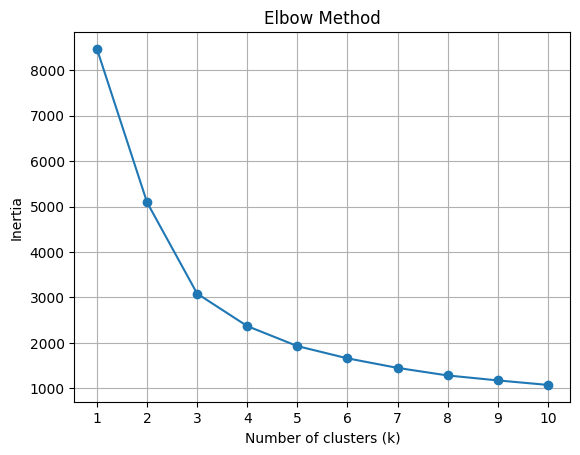

In [5]:
inertia_values = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.plot(range(1, 11), inertia_values, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nAverage sales features in each cluster:")
print(df.groupby("Cluster")[features].mean().round(2))

Cluster counts:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64

Average sales features in each cluster:
         QUANTITYORDERED  PRICEEACH    SALES
Cluster                                     
0                  35.13      57.13  2009.83
1                  43.85      96.64  5584.01
2                  27.39      94.87  3089.15


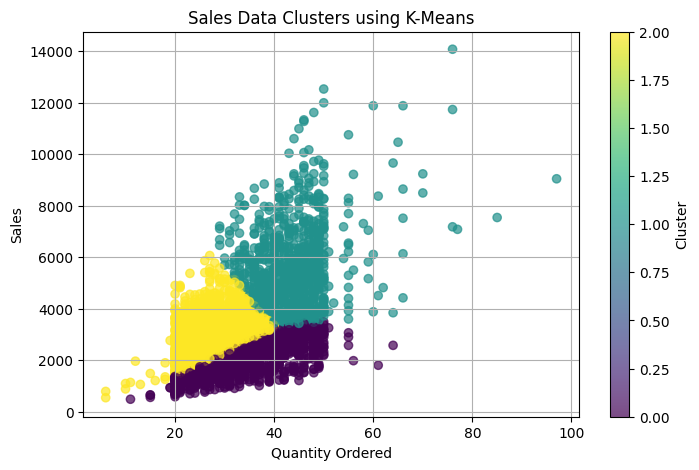

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["QUANTITYORDERED"],
    df["SALES"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("Sales Data Clusters using K-Means")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

## Practical 6 — Likely Viva Questions and Answers

1. **What is the aim of this practical?**  
   To group similar sales records using K-Means clustering and choose the number of groups with the elbow method.

2. **What is clustering?**  
   Clustering groups similar data points together without using preassigned labels.

3. **Is K-Means supervised or unsupervised?**  
   Unsupervised. The data has no target labels for the model to learn.

4. **Which features did you use?**  
   `QUANTITYORDERED`, `PRICEEACH`, and `SALES`.

5. **Why did you leave out order numbers and customer details?**  
   They identify or describe records, but aren’t useful numerical measures for grouping sales patterns.

6. **Why did you scale the features?**  
   The features have different numeric ranges. Scaling helps prevent a larger-range feature from dominating the distance calculations.

7. **What is a centroid?**  
   The center point representing a cluster.

8. **How does K-Means assign records to clusters?**  
   It assigns each record to the cluster whose centroid is nearest.

9. **What does K represent?**  
   The number of clusters to create.

10. **What is the elbow method?**  
    It plots the model’s inertia for different values of K to help select a suitable cluster count.

11. **What is inertia?**  
    The total squared distance between records and the centroids of their assigned clusters. Lower inertia means records are closer to their centroids.

12. **Why did you choose K = 3?**  
    The elbow graph’s decrease in inertia becomes less steep around three clusters.

13. **What are your three clusters like?**  
    Based on their averages, Cluster 0 has the lowest average sales, Cluster 1 the highest, and Cluster 2 falls between them.

14. **Do the cluster numbers have a fixed meaning?**  
    No. The numbers are arbitrary labels; they can change between runs or setups.

15. **What is one limitation of K-Means?**  
    You must choose K in advance, and results can be affected by scaling, outliers, and the initial centroid positions.